# 셀 준비

In [1]:
import pandas as pd
from sklearn import set_config

set_config(display="text")
from sklearn.linear_model import LinearRegression # 모델의 모양을 결정하는 알고리즘 중 선형 회귀 모델
from sklearn.metrics import mean_absolute_error # 오차를 계산하는 방식 중 하나
# 학습을 시킬 때 데이터를 훈련 데이터와 테스트 데이터로 나누어야 함
# 왜 나눔? 모든 데이터를 훈련 시키면 결과가 어떤지 실제 값이 나오기 전까진 확인 할 수 없음
from sklearn.model_selection import train_test_split # 데이터를 훈련, 테스트 데이터로 나눠줌(8:2)
from sklearn.neighbors import KNeighborsRegressor # 모델의 모양을 결정하는 알고리즘 중 K이웃회귀 모델
from sklearn.preprocessing import StandardScaler # 스케일링. 다양한 범위의 값들을 평균 0 표준편차 1로 만드는 것

# 시각화에 필요한 라이브러리
import platform 
import matplotlib.pyplot as plt

# 그래프 한글 깨짐 방지
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

# 데이터 불러오기

In [3]:
# csv 파일을 읽어서 DataFrame으로 바꿈. 한글 깨짐을 방지
df = pd.read_csv("study_scores.csv", encoding="utf-8")
# DataFrame 형태. (데이터 개수, 열 개수). 열 : 특징 + 결과
print(df.shape)
df.head() # 데이터 중 위에서 5개

(200, 5)


,study_hours,sleep_hours,phone_min,place,score
0,0.9,7.9,175,집,34
1,2.4,6.4,111,카페,45
2,8.0,4.1,141,집,69
3,5.8,6.7,79,도서관,72
4,0.9,8.3,159,도서관,36


# 데이터 그래프로 확인하기

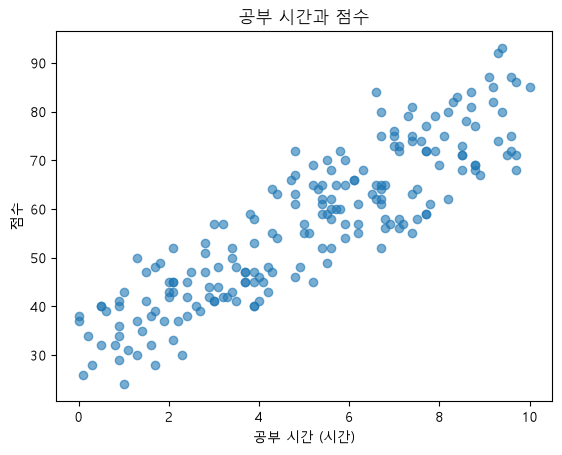

In [5]:
# 학습시간에 따른 공부의 상관관계를 보여주기
plt.scatter(df["study_hours"], df["score"], alpha=0.6) # 점을 찍음. x좌표는 공부시간, y좌표는 성적
plt.xlabel("공부 시간 (시간)")
plt.ylabel("점수")
plt.title("공부 시간과 점수")
plt.show() # 그래프 보여주기

# 1. 공부 시간에 따른 성적 예측하기

## 1.1. 데이터 선택

In [7]:
X = df[["study_hours"]] # 특징 : 공부 시간
y = df["score"] # 정답 : 성적

## 1.2. 훈련, 테스트 데이터 분리

In [8]:
# train_test_split : 4개의 값을 리턴
# 1번째 : 훈련 데이터(특징)
# 2번째 : 테스트 데이터(특징)
# 3번째 : 훈련 데이터(정답)
# 4번째 : 테스트 데이터(정답)
# test_size : 훈련 데이터 vs 테스터 데이터 비율. 0.2 => 테스트 데이터를 20%, 훈련을 80%
# random_state : 훈련과 테스트 데이터를 나눌 때 반영할 랜덤 값.
#                이 값이 같으면 매번 나누는 데이터가 같음 => 보통은 고정으로 안함
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
X_train.shape # 200개 중 80%인 160개

(160, 1)

## 1.3. 데이터 학습
### 선형회귀
* 예측하기 위한 최적의 직선을 찾음
* 직선을 나타내는 수식 : y = wX + b
* 학습을 하면 최적의 w와 b를 찾음

In [14]:
model = LinearRegression() # 알고리즘 선택(선형회귀)
model.fit(X_train, y_train) # 학습

LinearRegression()

## 1.4. 최적의 직선 확인(다른 곳에선 이 과정 생략)
* 최적의 `w`와 `b`를 확인

In [15]:
print(f"w: {model.coef_[0]:.2f}")
print(f"b: {model.intercept_:.2f}")

w: 5.22
b: 30.56


## 1.5. 성능 평가

In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pred_train = model.predict(X_train) # X_train으로 예측한 값들
pred_test = model.predict(X_test) # X_test로 예측한 값들

# 오차 계산한 방법 소개(종류)
mae = mean_absolute_error(y_test, pred_test) # 평균 절대 오차. 절대 오차의 평균
rmse = mean_squared_error(y_test, pred_test) ** 0.5 # 루트 평균 오차의 제곱.  평균 오차의 제곱의 루트
r2 = r2_score(y_test, pred_test) # 1에 가까울수록 좋음

print(f"MAE : {mae:.1f}점")
print(f"RMSE: {rmse:.1f}점")
print(f"r2  : {r2:.2f}(1에 가까울 수록 좋음)")
print()
print(f"학습 데이터 MAE : {mean_absolute_error(y_train, pred_train):.1f}점")
print(f"시험 데이터 MAE : {mae:.1f}점")

MAE : 5.7점
RMSE: 6.5점
r2  : 0.80(1에 가까울 수록 좋음)

학습 데이터 MAE : 6.1점
시험 데이터 MAE : 5.7점


## 1.6. 예측

In [30]:
hours = [0, 0.5, 5, 10, 15]
pred_scores = model.predict(pd.DataFrame({"study_hours": hours}))

def check_score(score):
    if score < 0:
        return 0
    if score > 100:
        return 100
    return score
    
for i in range(len(hours)):
    print(f"{hours[i]}시간 공부하면 예상 성적 : {check_score(pred_scores[i]):.1f}점")

0시간 공부하면 예상 성적 : 30.6점
0.5시간 공부하면 예상 성적 : 33.2점
5시간 공부하면 예상 성적 : 56.7점
10시간 공부하면 예상 성적 : 82.8점
15시간 공부하면 예상 성적 : 100.0점


# 2. 성적 예측하기(공부시간,수면 시간, 스마트폰 사용 시간) 

## 2.1. 데이터 선택

In [31]:
X = df[["study_hours", "sleep_hours", "phone_min"]]
y = df["score"]

## 2.2. 훈련, 데이터 분리

In [32]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 2.3. 학습
* K이웃회귀 : 가장 가까운 주변 K개를 확인해서 예측
    => 거리 계산
    => 스케일링을 안 하면 특정 특징(숫자가 큰 특징)이 영향을 많이 줄 수 있음

In [35]:
# 학습(스케일링 안함)
knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(X_train, y_train)

# 스케일링 함
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train) # 스케일링
X_test_s = scaler.transform(X_test) # 스케일링

# 학습(스케일링 함)
knn2 = KNeighborsRegressor(n_neighbors=5)
knn2.fit(X_train_s, y_train)

KNeighborsRegressor()

## 2.4. 성능 평가

In [37]:
print(f"스케일링 X(학습) : 평균 오차 {mean_absolute_error(y_train, knn.predict(X_train)):.1f}점")
print(f"스케일링 X(실험) : 평균 오차 {mean_absolute_error(y_test, knn.predict(X_test)):.1f}점")
print(f"스케일링 O(학습) : 평균 오차 {mean_absolute_error(y_train, knn2.predict(X_train_s)):.1f}점")
print(f"스케일링 O(실험) : 평균 오차 {mean_absolute_error(y_test, knn2.predict(X_test_s)):.1f}점")

스케일링 X(학습) : 평균 오차 8.1점
스케일링 X(실험) : 평균 오차 9.8점
스케일링 O(학습) : 평균 오차 3.8점
스케일링 O(실험) : 평균 오차 4.9점


## 2.5. 예측

In [38]:
df.columns

Index(['study_hours', 'sleep_hours', 'phone_min', 'place', 'score'], dtype='str')

In [40]:
hours = [0, 0.5, 5, 10, 10]
sleep_hours = [4, 8, 4, 4, 9]
phone_mins = [0, 60, 120, 0, 200]
# 예측
pred_scores = knn2.predict(pd.DataFrame({
    "study_hours": hours, 
    "sleep_hours":sleep_hours, 
    "phone_min" :phone_mins
}))

def check_score(score):
    if score < 0:
        return 0
    if score > 100:
        return 100
    return score
    
for hour, s_hour, p_hour, p_score in zip(hours, sleep_hours, phone_mins, pred_scores):
    print(f"공부: {hour}시간, 잠:{s_hour}시간, 폰:{p_hour/60:.1f}시간,  예상 성적 : {check_score(p_score):.1f}점")

공부: 0시간, 잠:4시간, 폰:0.0시간,  예상 성적 : 53.2점
공부: 0.5시간, 잠:8시간, 폰:1.0시간,  예상 성적 : 58.2점
공부: 5시간, 잠:4시간, 폰:2.0시간,  예상 성적 : 62.8점
공부: 10시간, 잠:4시간, 폰:0.0시간,  예상 성적 : 84.6점
공부: 10시간, 잠:9시간, 폰:3.3시간,  예상 성적 : 62.8점


C:\Users\fastcampus\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but KNeighborsRegressor was fitted without feature names
  warnings.warn(


# 3. 성적 예측하기(공부시간,수면 시간, 스마트폰 사용 시간, 장소)

## 3.1. 데이터 선택

In [50]:
# 잘못된 방법으로 장소를 수치화
X = df[["study_hours", "sleep_hours", "phone_min"]].copy()
X["place"] = df["place"].map({"도서관": 0, "집": 1, "카페": 2}) # 원핫인코딩 아님. 잘못된 방법
y = df["score"]

X2 = df[["study_hours", "sleep_hours", "phone_min", "place"]].copy()

## 3.2. 사전 작업(스케일링 또는 원핫인코딩)

In [51]:
# 원핫 인코딩 장소를 수치화
# 1. place가 가지는 값들을 열로 만들고, 해당 열이면 1로 표현
# 2. 그 중 첫번째 열을 제거
# 의미 : 첫번째 열을 기준으로 비교. 
PLACES = ["집", "도서관", "카페"]   # 맨 앞(집)이 기준이 되어 열에서 빠진다
X2["place"] = pd.Categorical(X2["place"], categories=PLACES) # place의 값들을 카테고리화
# drop_first : 원핫 인코딩으로 수치화 한 후 첫번째 컬럼을 제거할지 말지
X2 = pd.get_dummies(X2, columns=["place"], dtype=int, drop_first=True) # 원핫인코딩

## 3.3. 훈련, 테스트 분리

In [52]:
# 원핫아님
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 원핫
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.2, random_state=42)

## 3.4. 학습

In [53]:
# 원핫아님
model1 = LinearRegression().fit(X_train, y_train)
# 원핫
model2 = LinearRegression().fit(X2_train, y2_train)

## 3.5. 성능 평가

In [54]:
print(f"원핫 X(학습) : 평균 오차 {mean_absolute_error(y_train, model1.predict(X_train)):.1f}점")
print(f"원핫 X(실험) : 평균 오차 {mean_absolute_error(y_test, model1.predict(X_test)):.1f}점")
print(f"원핫 O(학습) : 평균 오차 {mean_absolute_error(y_train, model2.predict(X2_train)):.1f}점")
print(f"원핫 O(실험) : 평균 오차 {mean_absolute_error(y_test, model2.predict(X2_test)):.1f}점")

원핫 X(학습) : 평균 오차 3.6점
원핫 X(실험) : 평균 오차 4.0점
원핫 O(학습) : 평균 오차 3.1점
원핫 O(실험) : 평균 오차 3.3점


## 3.6. 예측

In [59]:
hours = [5, 5, 5]
sleep_hours = [6, 6, 6]
phone_min = [0, 0, 0]
place = ["집","도서관","카페"]
# 예측을 위한 DataFrame
me_X = pd.DataFrame({
    "study_hours": hours, 
    "sleep_hours":sleep_hours, 
    "phone_min" :phone_min,
    "place": place
})
# 원 핫 인코딩
me_X["place"] = pd.Categorical(me_X["place"], categories=PLACES) 
me_X = pd.get_dummies(me_X, columns=["place"], dtype=int, drop_first=True) 

# 예측
pred_scores = model2.predict(me_X)

def check_score(score):
    if score < 0:
        return 0
    if score > 100:
        return 100
    return score
    
for hour, s_hour, p_hour, p_score, pl in zip(
    hours, sleep_hours, phone_min, pred_scores, place):
    print(f"공부: {hour}시간, 잠:{s_hour}시간, 폰:{p_hour/60:.1f}시간, 장소:{pl},  예상 성적 : {check_score(p_score):.1f}점")

공부: 5시간, 잠:6시간, 폰:0.0시간, 장소:집,  예상 성적 : 59.7점
공부: 5시간, 잠:6시간, 폰:0.0시간, 장소:도서관,  예상 성적 : 66.1점
공부: 5시간, 잠:6시간, 폰:0.0시간, 장소:카페,  예상 성적 : 62.8점
